In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"00_preprocessed_2500inst.csv")

In [ ]:
TARGET_COL = "avg_cpu"

FEATURE_COLS = [
    "avg_cpu",
    "avg_mem",
    "max_cpu",
    "max_mem",
    "sample_cpu",
    "page_cache_memory",
    "assigned_memory",
    "sample_rate"
]

TIME_COL = "time_step"
INSTANCE_COL = "instance_id"
N_LAGS = 5

In [ ]:
def make_supervised_per_instance(inst_df, feature_cols, target_col, n_lags):
    inst_df = inst_df.sort_values(TIME_COL)

    X = inst_df[feature_cols]
    y = inst_df[target_col]

    lagged = []
    for i in range(1, n_lags + 1):
        lagged.append(X.shift(i).add_suffix(f"_t-{i}"))

    supervised = pd.concat(
    lagged + [
        y.rename("target"),
        inst_df[TIME_COL].rename("time_step")
    ],
    axis=1
    )
    supervised = supervised.iloc[n_lags:]
    supervised[INSTANCE_COL] = inst_df[INSTANCE_COL].iloc[n_lags:].values

    return supervised


supervised_parts = []

for inst_id, inst_df in df.groupby(INSTANCE_COL):
    if len(inst_df) <= 10:
        continue

    supervised_parts.append(
        make_supervised_per_instance(
            inst_df, FEATURE_COLS, TARGET_COL, N_LAGS
        )
    )

supervised_data = pd.concat(supervised_parts, ignore_index=True)

In [ ]:
instances = supervised_data[INSTANCE_COL].unique()
n = len(instances)

train_ids = instances[:int(0.7 * n)]
val_ids   = instances[int(0.7 * n):int(0.85 * n)]
test_ids  = instances[int(0.85 * n):]

train = supervised_data[supervised_data[INSTANCE_COL].isin(train_ids)]
val   = supervised_data[supervised_data[INSTANCE_COL].isin(val_ids)]
test  = supervised_data[supervised_data[INSTANCE_COL].isin(test_ids)]

test_time_steps = test[TIME_COL].values
test_instance_ids = test[INSTANCE_COL].values

X_train = train.drop(columns=["target", INSTANCE_COL]).values
y_train = train["target"].values

X_val = val.drop(columns=["target", INSTANCE_COL]).values
y_val = val["target"].values

X_test = test.drop(columns=["target", INSTANCE_COL]).values
y_test = test["target"].values

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train = scaler_X.fit_transform(X_train)
X_val   = scaler_X.transform(X_val)
X_test  = scaler_X.transform(X_test)

y_train = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_val   = scaler_y.transform(y_val.reshape(-1, 1)).ravel()
y_test  = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

In [ ]:
n_features = X_train.shape[1]

X_train = X_train.reshape(X_train.shape[0], 1, n_features)
X_val   = X_val.reshape(X_val.shape[0],   1, n_features)
X_test  = X_test.reshape(X_test.shape[0],  1, n_features)

In [ ]:
import pennylane as qml
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import numpy as np

N_QUBITS = 8
N_Q_LAYERS = 2

dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="tf")
def quantum_circuit(inputs, weights):

    # ---------- Encoding ----------
    for i in range(N_QUBITS):
        qml.RY(inputs[:, i] * np.pi, wires=i)
        qml.RZ(inputs[:, i] * np.pi, wires=i)

    # ---------- Variational layers ----------
    for l in range(N_Q_LAYERS):
        for i in range(N_QUBITS):
            qml.RX(weights[l, i, 0], wires=i)
            qml.RY(weights[l, i, 1], wires=i)

        # ---------- Entanglement ----------
        for i in range(0, N_QUBITS - 1, 2):
            qml.CNOT(wires=[i, i + 1])
        for i in range(1, N_QUBITS - 1, 2):
            qml.CNOT(wires=[i, i + 1])

    # ---------- Measurement ----------
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

In [ ]:
weight_shapes = {
    "weights": (N_Q_LAYERS, N_QUBITS, 2)
}

quantum_layer = qml.qnn.KerasLayer(
    quantum_circuit,
    weight_shapes,
    output_dim=N_QUBITS
)

In [ ]:
inp = layers.Input(shape=(1, n_features))

x = layers.Bidirectional(layers.GRU(128))(inp)
x = layers.Dense(16, activation="relu")(x)
x = layers.Dense(N_QUBITS, activation="tanh")(x)
x = quantum_layer(x)
out = layers.Dense(1)(x)

model = Model(inp, out)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.0001),
    loss="mse"
)

In [ ]:
# =========================
# 8. TRAIN
# =========================
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=101,
    batch_size=128,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/101
608/608 [==============================] - 488s 803ms/step - loss: 0.0338 - val_loss: 0.0013
Epoch 2/101
608/608 [==============================] - 487s 802ms/step - loss: 0.0096 - val_loss: 0.0013
Epoch 3/101
608/608 [==============================] - 488s 803ms/step - loss: 0.0095 - val_loss: 0.0013
Epoch 4/101
608/608 [==============================] - 488s 804ms/step - loss: 0.0094 - val_loss: 0.0013
Epoch 5/101
608/608 [==============================] - 489s 804ms/step - loss: 0.0093 - val_loss: 0.0013
Epoch 6/101
608/608 [==============================] - 488s 803ms/step - loss: 0.0093 - val_loss: 0.0013
Epoch 7/101
608/608 [==============================] - 487s 802ms/step - loss: 0.0092 - val_loss: 0.0013
Epoch 8/101
608/608 [==============================] - 487s 801ms/step - loss: 0.0092 - val_loss: 0.0012
Epoch 9/101
608/608 [==============================] - 489s 805ms/step - loss: 0.0091 - val_loss: 0.0012
Epoch 10/101
608/608 [==============================] -

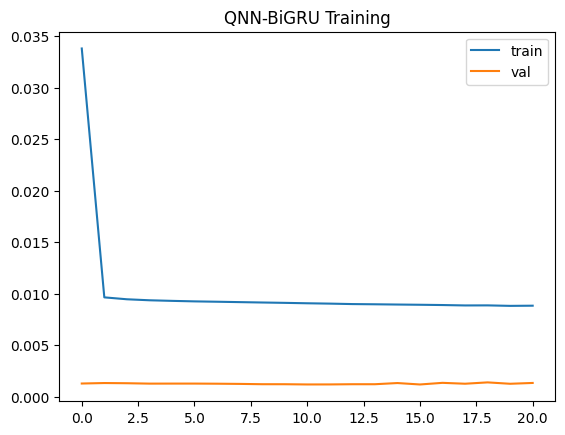

In [ ]:
# =========================
# 9. PLOTS
# =========================
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.legend()
plt.title("QNN-BiGRU Training")
plt.show()

In [ ]:
y_pred_scaled = model.predict(X_test)

y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_true = scaler_y.inverse_transform(y_test.reshape(-1,1))

1056/1056 [==============================] - 287s 272ms/step


In [ ]:
# 🔑 VERY IMPORTANT: flatten everything
y_pred = np.asarray(y_pred).reshape(-1)
y_true = np.asarray(y_true).reshape(-1)

In [ ]:
import numpy as np
import math
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    median_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    explained_variance_score
)

def compute_metrics(y_true, y_pred):
    # Basic errors
    mse  = mean_squared_error(y_true, y_pred)
    rmse = math.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    medae = median_absolute_error(y_true, y_pred)

    # Relative (use with caution)
    mape = mean_absolute_percentage_error(y_true, y_pred)

    smape = np.mean(
        2 * np.abs(y_pred - y_true) /
        (np.abs(y_true) + np.abs(y_pred) + 1e-8)
    )

    # Scale-aware (safe alternative to MAPE)
    nmae = mae / (np.mean(np.abs(y_true)) + 1e-8)

    # Goodness of fit
    r2 = r2_score(y_true, y_pred)
    evs = explained_variance_score(y_true, y_pred)

    # Correlation (trend alignment)
    corr = np.corrcoef(y_true, y_pred)[0, 1]

    # Bias
    bias = np.mean(y_pred - y_true)

    # Error distribution
    abs_err = np.abs(y_true - y_pred)
    err_p50, err_p75, err_p90, err_p95 = np.percentile(
        abs_err, [50, 75, 90, 95]
    )

    return {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "Median_AE": medae,
        "MAPE": mape,          # not reliable if y_true ≈ 0
        "sMAPE": smape,
        "NMAE": nmae,
        "R2": r2,
        "Explained_Variance": evs,
        "Correlation": corr,
        "Bias": bias,
        "Err_P50": err_p50,
        "Err_P75": err_p75,
        "Err_P90": err_p90,
        "Err_P95": err_p95
    }


# Compute metrics
metrics = compute_metrics(y_true, y_pred)

# Print results
print(f"Test MSE   : {metrics['MSE']:.6f}")
print(f"Test RMSE  : {metrics['RMSE']:.6f}")
print(f"Test MAE   : {metrics['MAE']:.6f}")
print(f"Test MedAE : {metrics['Median_AE']:.6f}")

print(f"Test MAPE  : {metrics['MAPE'] * 100:.2f}%  (⚠ unreliable if y_true ≈ 0)")
print(f"Test sMAPE : {metrics['sMAPE'] * 100:.2f}%")
print(f"Test NMAE  : {metrics['NMAE'] * 100:.2f}%")

print(f"Test R²    : {metrics['R2']:.4f}")
print(f"Expl.Var   : {metrics['Explained_Variance']:.4f}")
print(f"Corr(y,ŷ)  : {metrics['Correlation']:.4f}")

print(f"Bias       : {metrics['Bias']:.6f}")

print("Error percentiles:")
print(f"  50% | 75% | 90% | 95%")
print(f"  {metrics['Err_P50']:.6f} | {metrics['Err_P75']:.6f} | "
      f"{metrics['Err_P90']:.6f} | {metrics['Err_P95']:.6f}")

Test MSE   : 0.000006
Test RMSE  : 0.002388
Test MAE   : 0.001583
Test MedAE : 0.000746
Test MAPE  : 4044335986285.68%  (⚠ unreliable if y_true ≈ 0)
Test sMAPE : 70.59%
Test NMAE  : 57.41%
Test R²    : 0.5617
Expl.Var   : 0.5684
Corr(y,ŷ)  : 0.7540
Bias       : -0.000297
Error percentiles:
  50% | 75% | 90% | 95%
  0.000746 | 0.002669 | 0.004340 | 0.005182
